# Perceptron Learning Assignment


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
veri1 = pd.read_csv("first_problem.csv")
veri2 = pd.read_csv("second_problem.csv")

print("first_problem boyutu:", veri1.shape)
print(veri1["label"].value_counts())
print()
print("second_problem boyutu:", veri2.shape)
print(veri2["label"].value_counts())

first_problem boyutu: (400, 3)
label
0    200
1    200
Name: count, dtype: int64

second_problem boyutu: (194, 3)
label
1    97
0    97
Name: count, dtype: int64


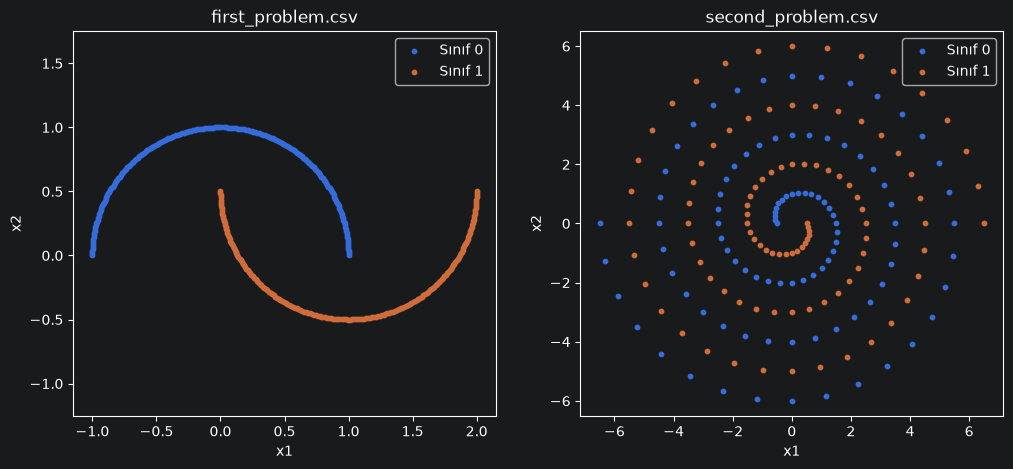

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

for i, veri in enumerate([veri1, veri2]):
    sinif0 = veri[veri["label"] == 0]
    sinif1 = veri[veri["label"] == 1]
    ax[i].scatter(sinif0["x1"], sinif0["x2"], s=10, label="Sınıf 0")
    ax[i].scatter(sinif1["x1"], sinif1["x2"], s=10, label="Sınıf 1")
    ax[i].set_xlabel("x1")
    ax[i].set_ylabel("x2")
    ax[i].axis("equal")
    ax[i].legend()

ax[0].set_title("first_problem.csv")
ax[1].set_title("second_problem.csv")
plt.show()

Both datasets are not linearly separable. Labels are changed from 0/1 to -1/+1.

In [4]:
X1 = veri1[["x1", "x2"]].values
y1 = np.where(veri1["label"].values == 1, 1, -1)
X2 = veri2[["x1", "x2"]].values
y2 = np.where(veri2["label"].values == 1, 1, -1)

print(y1[:10])

[-1  1  1 -1  1 -1 -1  1 -1  1]


In [5]:
def sign_aktivasyon(z):
    return np.where(z >= 0, 1, -1)


def veriyi_bol(X, y, egitim_orani, seed):
    np.random.seed(seed)
    karisik = np.random.permutation(len(X))
    sinir = int(len(X) * egitim_orani)
    egitim = karisik[:sinir]
    test = karisik[sinir:]
    return X[egitim], y[egitim], X[test], y[test]


def standartlastir(X_egitim, X_test):
    ortalama = X_egitim.mean(axis=0)
    std = X_egitim.std(axis=0)
    return (X_egitim - ortalama) / std, (X_test - ortalama) / std

In [6]:
def gizli_katmanlari_olustur(gizli_noronlar, seed, bias_turu="sifir"):
    np.random.seed(seed)
    agirliklar = []
    biaslar = []
    girdi_sayisi = 2
    for noron_sayisi in gizli_noronlar:
        W = np.random.normal(0, np.sqrt(2.0 / girdi_sayisi), (noron_sayisi, girdi_sayisi))
        if bias_turu == "sifir":
            b = np.zeros((noron_sayisi, 1))
        else:
            b = np.random.normal(0, np.sqrt(2.0 / girdi_sayisi), (noron_sayisi, 1))
        agirliklar.append(W)
        biaslar.append(b)
        girdi_sayisi = noron_sayisi
    return agirliklar, biaslar


def gizli_katmanlardan_gecir(X, agirliklar, biaslar):
    cikti = X.T
    for i in range(len(agirliklar)):
        cikti = np.tanh(agirliklar[i] @ cikti + biaslar[i])
    return cikti.T

In [7]:
def tahmin_et(H, W, b):
    return sign_aktivasyon(H @ W.T + b).ravel()


def dogruluk(H, y, W, b):
    return np.mean(tahmin_et(H, W, b) == y)


def cikis_katmanini_egit(H, y, eta, epoch_sayisi, seed, baslangic="he", momentum=0.9, batch_size=2):
    np.random.seed(seed)
    n, girdi_sayisi = H.shape
    if baslangic == "he":
        W = np.random.normal(0, np.sqrt(2.0 / girdi_sayisi), (1, girdi_sayisi))
    else:
        W = np.zeros((1, girdi_sayisi))
    b = np.zeros((1, 1))
    onceki_guncelleme_W = np.zeros_like(W)
    onceki_guncelleme_b = np.zeros_like(b)
    gecmis = []

    for epoch in range(epoch_sayisi):
        sira = np.random.permutation(n)
        for i in range(0, n, batch_size):
            batch = sira[i:i + batch_size]
            dW = np.zeros_like(W)
            db = np.zeros_like(b)
            for j in batch:
                h = H[j].reshape(-1, 1)
                cikti = sign_aktivasyon(W @ h + b)
                hata = y[j] - cikti
                dW += hata @ h.T
                db += hata
            dW /= len(batch)
            db /= len(batch)

            guncelleme_W = eta * dW + momentum * onceki_guncelleme_W
            guncelleme_b = eta * db + momentum * onceki_guncelleme_b
            W += guncelleme_W
            b += guncelleme_b
            onceki_guncelleme_W = guncelleme_W
            onceki_guncelleme_b = guncelleme_b

        gecmis.append(dogruluk(H, y, W, b))

    return W, b, gecmis

In [8]:
def deney_yap(X, y, gizli_noronlar, eta, epoch_sayisi, seed, baslangic="he", bias_turu="sifir"):
    X_egitim, y_egitim, X_test, y_test = veriyi_bol(X, y, 0.7, seed)
    X_egitim, X_test = standartlastir(X_egitim, X_test)
    agirliklar, biaslar = gizli_katmanlari_olustur(gizli_noronlar, seed + 100, bias_turu)
    H_egitim = gizli_katmanlardan_gecir(X_egitim, agirliklar, biaslar)
    H_test = gizli_katmanlardan_gecir(X_test, agirliklar, biaslar)
    W, b, gecmis = cikis_katmanini_egit(H_egitim, y_egitim, eta, epoch_sayisi, seed + 200, baslangic)
    egitim_dogrulugu = dogruluk(H_egitim, y_egitim, W, b)
    test_dogrulugu = dogruluk(H_test, y_test, W, b)
    return egitim_dogrulugu, test_dogrulugu, gecmis

### XOR check

Given settings (2-4-1, η = 0.1, 1000 epochs) without backpropagation, with hidden bias 0 and random.

In [9]:
X_xor = np.array([[1, 1], [1, -1], [-1, 1], [-1, -1]])
y_xor = np.array([-1, 1, 1, -1])

satirlar = []
for seed in range(10):
    satir = [seed]
    for bias_turu in ["sifir", "rastgele"]:
        agirliklar, biaslar = gizli_katmanlari_olustur([4], seed, bias_turu)
        H_xor = gizli_katmanlardan_gecir(X_xor, agirliklar, biaslar)
        W, b, gecmis = cikis_katmanini_egit(H_xor, y_xor, 0.1, 1000, seed)
        satir.append(dogruluk(H_xor, y_xor, W, b))
        satir.append(max(gecmis))
    satirlar.append(satir)

tablo_xor = pd.DataFrame(satirlar, columns=["seed", "son (bias 0)", "en iyi (bias 0)", "son (bias rastgele)", "en iyi (bias rastgele)"])
tablo_xor

,seed,son (bias 0),en iyi (bias 0),son (bias rastgele),en iyi (bias rastgele)
0,0,0.50,0.75,1.0,1.0
1,1,0.50,0.75,1.0,1.0
2,2,0.75,0.75,1.0,1.0
3,3,0.50,0.75,1.0,1.0
4,4,0.50,0.75,1.0,1.0
5,5,0.50,0.75,1.0,1.0
6,6,0.50,0.75,1.0,1.0
7,7,0.50,0.75,1.0,1.0
8,8,0.50,0.75,1.0,1.0
9,9,0.50,0.75,1.0,1.0


With bias 0 the accuracy is at most 75%: since $h(-x) = -h(x)$, the output bias would need to be both $< 0$ and $\ge 0$. With random bias, XOR is solved for all 10 seeds.

5 seeds, 100 epochs, 70% train / 30% test.

In [10]:
SEEDLER = [0, 1, 2, 3, 4]
EPOCH = 100
VARSAYILAN = [4]
VERILER = [("first_problem", X1, y1), ("second_problem", X2, y2)]

## Learning Rate

In [11]:
ogrenme_oranlari = [0.001, 0.01, 0.1, 1.0]

satirlar = []
for veri_adi, X, y in VERILER:
    for baslangic in ["he", "sifir"]:
        for eta in ogrenme_oranlari:
            egitim_sonuclari = []
            test_sonuclari = []
            for seed in SEEDLER:
                egitim_dog, test_dog, gecmis = deney_yap(X, y, VARSAYILAN, eta, EPOCH, seed, baslangic)
                egitim_sonuclari.append(egitim_dog)
                test_sonuclari.append(test_dog)
            satirlar.append([veri_adi, baslangic, eta,
                             round(np.mean(egitim_sonuclari), 3),
                             round(np.mean(test_sonuclari), 3),
                             round(np.std(test_sonuclari), 3)])

tablo_eta = pd.DataFrame(satirlar, columns=["veri", "başlangıç", "eta", "eğitim ort.", "test ort.", "test std"])
tablo_eta

,veri,başlangıç,eta,eğitim ort.,test ort.,test std
0,first_problem,he,0.001,0.980,0.982,0.033
1,first_problem,he,0.010,0.979,0.985,0.030
2,first_problem,he,0.100,0.989,0.990,0.020
3,first_problem,he,1.000,0.961,0.975,0.050
4,first_problem,sifir,0.001,0.982,0.982,0.037
5,first_problem,sifir,0.010,0.982,0.982,0.037
6,first_problem,sifir,0.100,0.982,0.982,0.037
7,first_problem,sifir,1.000,0.982,0.982,0.037
8,second_problem,he,0.001,0.520,0.481,0.067
9,second_problem,he,0.010,0.544,0.481,0.075


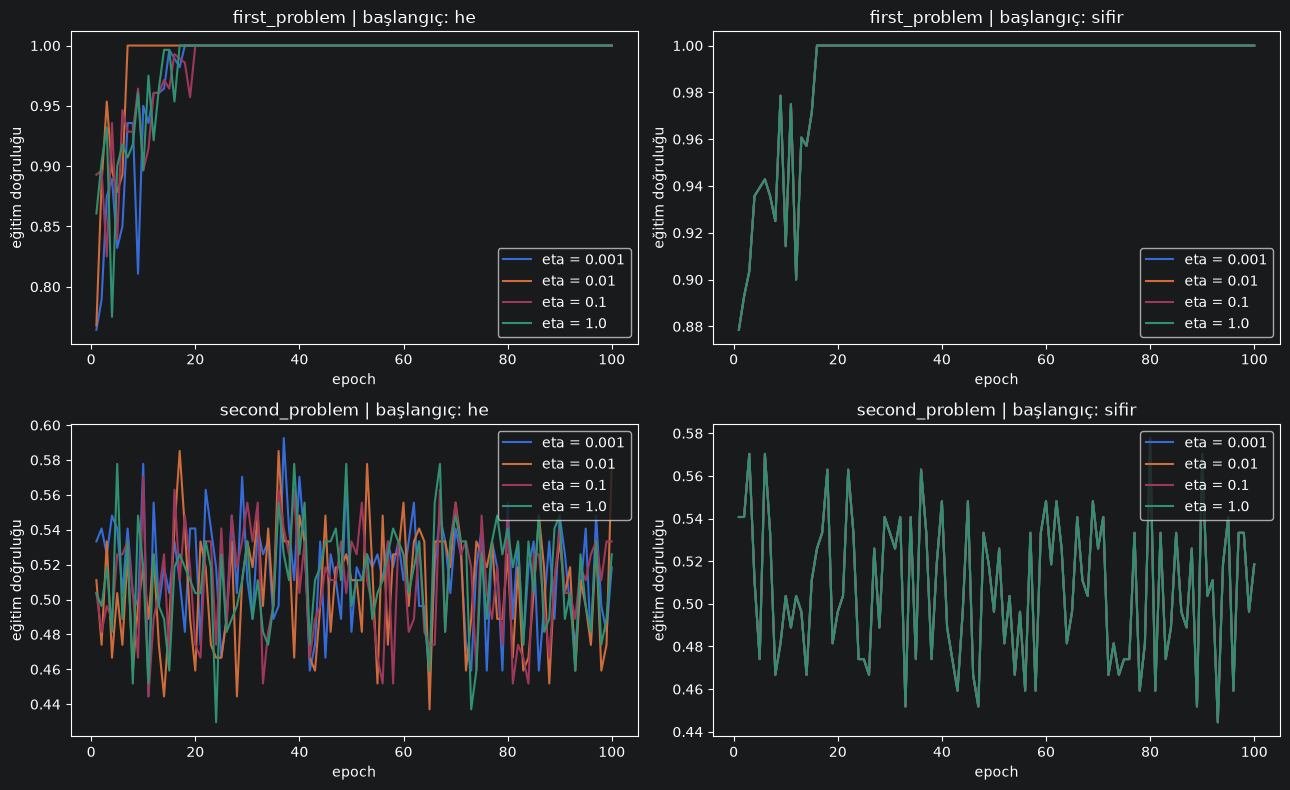

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))

for satir, (veri_adi, X, y) in enumerate(VERILER):
    for sutun, baslangic in enumerate(["he", "sifir"]):
        for eta in ogrenme_oranlari:
            egitim_dog, test_dog, gecmis = deney_yap(X, y, VARSAYILAN, eta, EPOCH, 0, baslangic)
            ax[satir, sutun].plot(range(1, EPOCH + 1), gecmis, label="eta = " + str(eta))
        ax[satir, sutun].set_title(veri_adi + " | başlangıç: " + baslangic)
        ax[satir, sutun].set_xlabel("epoch")
        ax[satir, sutun].set_ylabel("eğitim doğruluğu")
        ax[satir, sutun].legend()

plt.tight_layout()
plt.show()

With zero initialization all η values give the same result, because $\text{sign}(W h)$ does not change when $W$ is scaled. With He initialization the differences are small (0.975 to 0.990 on `first_problem`, 0.475 to 0.488 on `second_problem`) and there is no trend. So changing η does not consistently improve performance.

### Hebbian rule comparison

In [13]:
def hebb_egit(H, y, eta):
    W = np.zeros((1, H.shape[1]))
    b = np.zeros((1, 1))
    for j in range(len(H)):
        h = H[j].reshape(-1, 1)
        W += eta * y[j] * h.T
        b += eta * y[j]
    return W, b


satirlar = []
for veri_adi, X, y in VERILER:
    perceptron_test = []
    hebb_test = []
    for seed in SEEDLER:
        X_egitim, y_egitim, X_test, y_test = veriyi_bol(X, y, 0.7, seed)
        X_egitim, X_test = standartlastir(X_egitim, X_test)
        agirliklar, biaslar = gizli_katmanlari_olustur(VARSAYILAN, seed + 100)
        H_egitim = gizli_katmanlardan_gecir(X_egitim, agirliklar, biaslar)
        H_test = gizli_katmanlardan_gecir(X_test, agirliklar, biaslar)
        W_p, b_p, gecmis = cikis_katmanini_egit(H_egitim, y_egitim, 0.1, EPOCH, seed + 200)
        W_h, b_h = hebb_egit(H_egitim, y_egitim, 0.1)
        perceptron_test.append(dogruluk(H_test, y_test, W_p, b_p))
        hebb_test.append(dogruluk(H_test, y_test, W_h, b_h))
    satirlar.append([veri_adi, "Perceptron (verilen kural)", round(np.mean(perceptron_test), 3), round(np.std(perceptron_test), 3)])
    satirlar.append([veri_adi, "Hebb", round(np.mean(hebb_test), 3), round(np.std(hebb_test), 3)])

tablo_hebb = pd.DataFrame(satirlar, columns=["veri", "kural", "test ort.", "test std"])
tablo_hebb

,veri,kural,test ort.,test std
0,first_problem,Perceptron (verilen kural),0.990,0.020
1,first_problem,Hebb,0.813,0.049
2,second_problem,Perceptron (verilen kural),0.475,0.037
3,second_problem,Hebb,0.424,0.015


Perceptron 0.990 vs Hebb 0.813 on `first_problem`. Both fail on `second_problem`.

## Architecture Comparison

Default: 2-4-1 (η = 0.1). 2-1 has no hidden layer.

In [14]:
mimariler = {
    "2-1": [],
    "2-2-1": [2],
    "2-4-1 (varsayılan)": [4],
    "2-16-1": [16],
    "2-64-1": [64],
    "2-256-1": [256],
    "2-4-4-1": [4, 4],
    "2-16-16-1": [16, 16],
}

satirlar = []
for veri_adi, X, y in VERILER:
    for mimari_adi, gizli_noronlar in mimariler.items():
        egitim_sonuclari = []
        test_sonuclari = []
        for seed in SEEDLER:
            egitim_dog, test_dog, gecmis = deney_yap(X, y, gizli_noronlar, 0.1, EPOCH, seed)
            egitim_sonuclari.append(egitim_dog)
            test_sonuclari.append(test_dog)
        satirlar.append([veri_adi, mimari_adi,
                         round(np.mean(egitim_sonuclari), 3),
                         round(np.mean(test_sonuclari), 3),
                         round(np.std(test_sonuclari), 3)])

tablo_mimari = pd.DataFrame(satirlar, columns=["veri", "mimari", "eğitim ort.", "test ort.", "test std"])
tablo_mimari

,veri,mimari,eğitim ort.,test ort.,test std
0,first_problem,2-1,0.847,0.843,0.032
1,first_problem,2-2-1,0.819,0.792,0.160
2,first_problem,2-4-1 (varsayılan),0.989,0.990,0.020
3,first_problem,2-16-1,1.000,1.000,0.000
4,first_problem,2-64-1,1.000,1.000,0.000
5,first_problem,2-256-1,1.000,1.000,0.000
6,first_problem,2-4-4-1,0.951,0.957,0.048
7,first_problem,2-16-16-1,1.000,1.000,0.000
8,second_problem,2-1,0.529,0.447,0.038
9,second_problem,2-2-1,0.504,0.498,0.068


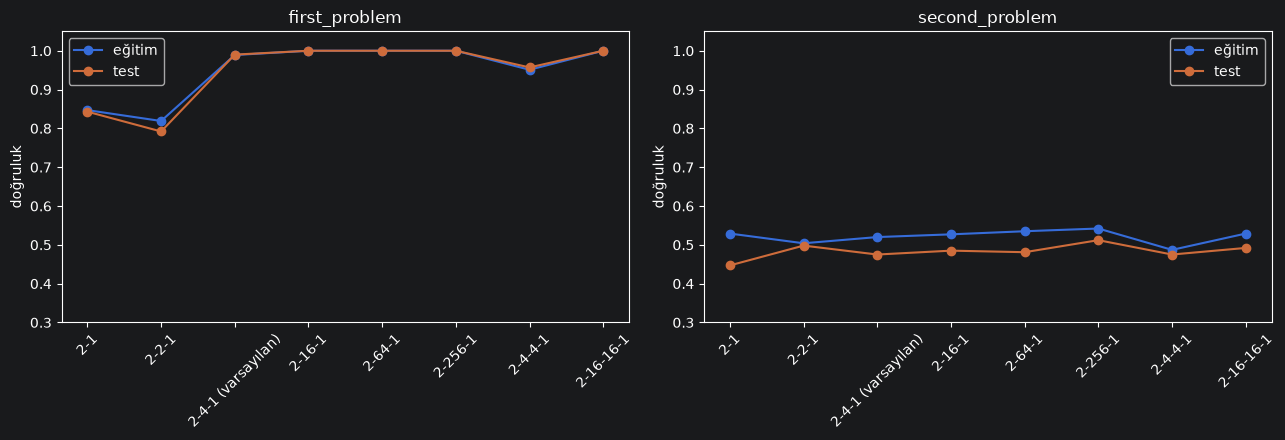

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

for i, (veri_adi, X, y) in enumerate(VERILER):
    alt_tablo = tablo_mimari[tablo_mimari["veri"] == veri_adi]
    ax[i].plot(alt_tablo["mimari"], alt_tablo["eğitim ort."], marker="o", label="eğitim")
    ax[i].plot(alt_tablo["mimari"], alt_tablo["test ort."], marker="o", label="test")
    ax[i].set_title(veri_adi)
    ax[i].set_ylabel("doğruluk")
    ax[i].set_ylim(0.3, 1.05)
    ax[i].tick_params(axis="x", rotation=45)
    ax[i].legend()

plt.tight_layout()
plt.show()

Decision boundaries (seed 0):

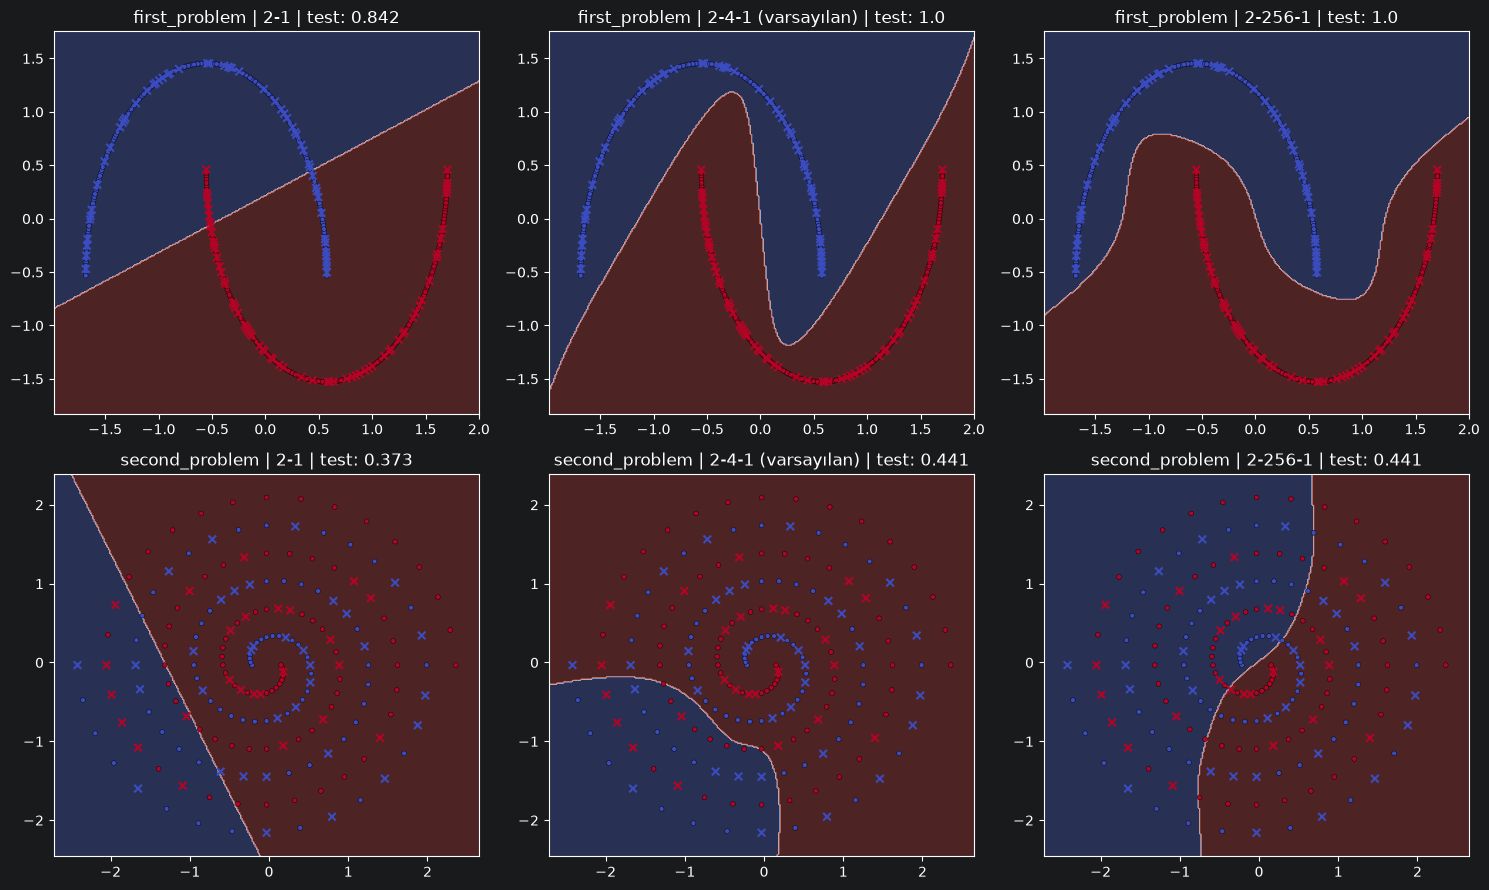

In [16]:
def karar_siniri_ciz(ax, X, y, gizli_noronlar, seed, baslik):
    X_egitim, y_egitim, X_test, y_test = veriyi_bol(X, y, 0.7, seed)
    X_egitim, X_test = standartlastir(X_egitim, X_test)
    agirliklar, biaslar = gizli_katmanlari_olustur(gizli_noronlar, seed + 100)
    H_egitim = gizli_katmanlardan_gecir(X_egitim, agirliklar, biaslar)
    W, b, gecmis = cikis_katmanini_egit(H_egitim, y_egitim, 0.1, EPOCH, seed + 200)

    tum_X = np.vstack([X_egitim, X_test])
    x_min, x_max = tum_X[:, 0].min() - 0.3, tum_X[:, 0].max() + 0.3
    y_min, y_max = tum_X[:, 1].min() - 0.3, tum_X[:, 1].max() + 0.3
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    izgara = np.column_stack([xx.ravel(), yy.ravel()])
    z = tahmin_et(gizli_katmanlardan_gecir(izgara, agirliklar, biaslar), W, b).reshape(xx.shape)

    H_test = gizli_katmanlardan_gecir(X_test, agirliklar, biaslar)
    test_dog = dogruluk(H_test, y_test, W, b)
    ax.contourf(xx, yy, z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_egitim[:, 0], X_egitim[:, 1], c=y_egitim, cmap="coolwarm", s=12, edgecolors="k", linewidths=0.3)
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="coolwarm", s=30, marker="x")
    ax.set_title(baslik + " | test: " + str(round(test_dog, 3)))


secilenler = ["2-1", "2-4-1 (varsayılan)", "2-256-1"]
fig, ax = plt.subplots(2, 3, figsize=(15, 9))

for satir, (veri_adi, X, y) in enumerate(VERILER):
    for sutun, mimari_adi in enumerate(secilenler):
        karar_siniri_ciz(ax[satir, sutun], X, y, mimariler[mimari_adi], 0, veri_adi + " | " + mimari_adi)

plt.tight_layout()
plt.show()

`first_problem`: 2-1 gets 0.843, 2-4-1 gets 0.990 and 16 or more neurons get 1.000. 2-2-1 (0.792) and 2-4-4-1 (0.957) are worse than simpler models.

`second_problem`: all between 0.447 and 0.512 (guessing level).

### Hidden bias: 0 or random

In [17]:
bias_mimarileri = ["2-2-1", "2-4-1 (varsayılan)", "2-16-1", "2-64-1", "2-256-1", "2-4-4-1", "2-16-16-1"]

satirlar = []
for veri_adi, X, y in VERILER:
    for mimari_adi in bias_mimarileri:
        for bias_turu in ["sifir", "rastgele"]:
            egitim_sonuclari = []
            test_sonuclari = []
            for seed in SEEDLER:
                egitim_dog, test_dog, gecmis = deney_yap(X, y, mimariler[mimari_adi], 0.1, EPOCH, seed, bias_turu=bias_turu)
                egitim_sonuclari.append(egitim_dog)
                test_sonuclari.append(test_dog)
            satirlar.append([veri_adi, mimari_adi, bias_turu,
                             round(np.mean(egitim_sonuclari), 3),
                             round(np.mean(test_sonuclari), 3),
                             round(np.std(test_sonuclari), 3)])

tablo_bias = pd.DataFrame(satirlar, columns=["veri", "mimari", "gizli bias", "eğitim ort.", "test ort.", "test std"])
tablo_bias

,veri,mimari,gizli bias,eğitim ort.,test ort.,test std
0,first_problem,2-2-1,sifir,0.819,0.792,0.160
1,first_problem,2-2-1,rastgele,0.628,0.597,0.156
2,first_problem,2-4-1 (varsayılan),sifir,0.989,0.990,0.020
3,first_problem,2-4-1 (varsayılan),rastgele,0.944,0.943,0.045
4,first_problem,2-16-1,sifir,1.000,1.000,0.000
5,first_problem,2-16-1,rastgele,1.000,1.000,0.000
6,first_problem,2-64-1,sifir,1.000,1.000,0.000
7,first_problem,2-64-1,rastgele,1.000,1.000,0.000
8,first_problem,2-256-1,sifir,1.000,1.000,0.000
9,first_problem,2-256-1,rastgele,1.000,1.000,0.000


Random bias is worse for small networks on `first_problem` (2-4-1: 0.990 → 0.943) and does not help on `second_problem`, so bias stays 0 in the main experiments.

## Adding Hidden Layers and Neurons

Adding hidden layers or neurons does not always help. Without backpropagation the hidden layer does not learn, so only the output perceptron learns and more neurons only add more random features. This is enough for `first_problem` but not for the spiral in `second_problem`. With few neurons (2-2-1) or an extra random layer (2-4-4-1) the results can even get worse.

## Best Results

In [18]:
noron_secenekleri = [[4], [16], [64], [256]]

satirlar = []
for veri_adi, X, y in VERILER:
    for gizli_noronlar in noron_secenekleri:
        for eta in ogrenme_oranlari:
            egitim_sonuclari = []
            test_sonuclari = []
            for seed in SEEDLER:
                egitim_dog, test_dog, gecmis = deney_yap(X, y, gizli_noronlar, eta, EPOCH, seed)
                egitim_sonuclari.append(egitim_dog)
                test_sonuclari.append(test_dog)
            mimari_adi = "2-" + str(gizli_noronlar[0]) + "-1"
            satirlar.append([veri_adi, mimari_adi, eta,
                             round(np.mean(egitim_sonuclari), 3),
                             round(np.mean(test_sonuclari), 3),
                             round(np.std(test_sonuclari), 3)])

tablo_arama = pd.DataFrame(satirlar, columns=["veri", "mimari", "eta", "eğitim ort.", "test ort.", "test std"])

for veri_adi, X, y in VERILER:
    alt_tablo = tablo_arama[tablo_arama["veri"] == veri_adi]
    en_iyi = alt_tablo.loc[alt_tablo["test ort."].idxmax()]
    print(veri_adi)
    print("  en iyi mimari   :", en_iyi["mimari"])
    print("  öğrenme oranı   :", en_iyi["eta"])
    print("  eğitim doğruluğu:", en_iyi["eğitim ort."])
    print("  test doğruluğu  :", en_iyi["test ort."], "±", en_iyi["test std"])
    print()

first_problem
  en iyi mimari   : 2-16-1
  öğrenme oranı   : 0.001
  eğitim doğruluğu: 1.0
  test doğruluğu  : 1.0 ± 0.0

second_problem
  en iyi mimari   : 2-16-1
  öğrenme oranı   : 0.001
  eğitim doğruluğu: 0.519
  test doğruluğu  : 0.532 ± 0.046



In [19]:
tablo_arama.pivot_table(index=["veri", "mimari"], columns="eta", values="test ort.")

eta                     0.001  0.010  0.100  1.000
veri           mimari                             
first_problem  2-16-1   1.000  1.000  1.000  1.000
               2-256-1  1.000  1.000  1.000  1.000
               2-4-1    0.982  0.985  0.990  0.975
               2-64-1   1.000  1.000  1.000  1.000
second_problem 2-16-1   0.532  0.512  0.485  0.488
               2-256-1  0.478  0.471  0.512  0.475
               2-4-1    0.481  0.481  0.475  0.488
               2-64-1   0.492  0.492  0.481  0.492

- `first_problem`: 1.000 (2-16-1)
- `second_problem`: 0.532 ± 0.046 (2-16-1, η = 0.001), guessing level

## Conclusion

The given rule is Rosenblatt at the output and backpropagation in the hidden layer. Without backpropagation, the network solves `first_problem` but not `second_problem`. Changing η or adding neurons does not consistently improve the results.